# Word Cloud

**Family:** Magnitude &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Magnitude:* Compare sizes, relative or absolute (usually counts rather than rates).

## Design purpose

Shows words from a text sized by their frequency. It gives an at-a-glance, impressionistic summary of the dominant terms in open-ended text.

## When to use

- Give a quick first look at the themes of free-text responses, reviews or speeches
- Engaging illustrations where precision is not required

## Avoid when

- Any analytical comparison (word size is confounded by word length; use a bar chart of frequencies)
- Small corpora, or text where key phrases span several words

## Alternatives

- Horizontal bar chart of top terms
- Treemap of topics

## Design tips

- Remove stop-words; use one or two colors instead of random rainbow colors
- Pair with a frequency bar chart for any real analysis

## Example

Word frequencies from app-store reviews of a mobile banking app (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
from collections import Counter
rng = np.random.default_rng(2)
vocab = {"easy": 40, "transfer": 34, "login": 30, "fast": 28, "fees": 26, "support": 24,
         "update": 22, "crash": 18, "secure": 16, "card": 15, "budget": 14, "savings": 12,
         "notifications": 11, "statement": 10, "investing": 9, "biometric": 8, "slow": 7,
         "exchange": 6, "interest": 6, "cashback": 5, "outage": 4, "verification": 4, "loan": 3}
freqs = {w: int(f * rng.uniform(0.8, 1.2)) for w, f in vocab.items()}
pd.Series(freqs).sort_values(ascending=False).head(10)

easy        36
login       33
transfer    31
fees        27
support     26
fast        23
update      19
card        15
crash       14
secure      14
dtype: int64

### Plot

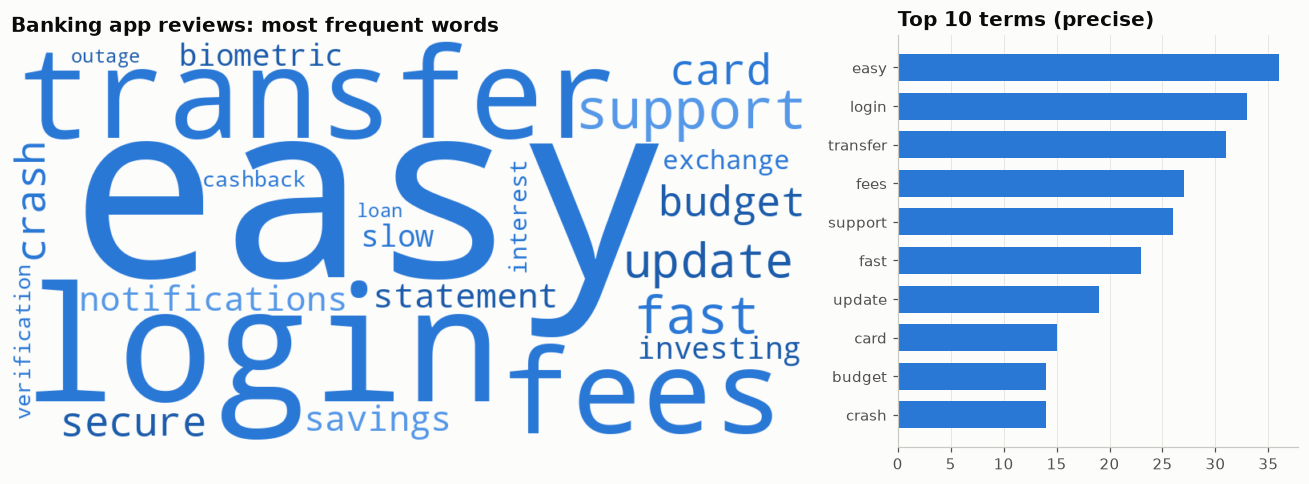

In [3]:
from wordcloud import WordCloud
blues = ["#104281", "#1c5cab", "#2a78d6", "#5598e7"]
wc = WordCloud(width=1000, height=500, background_color="#fcfcfb", prefer_horizontal=0.9,
               color_func=lambda *a, **k: blues[np.random.default_rng(len(a[0])).integers(4)],
               random_state=1).generate_from_frequencies(freqs)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [2, 1]})
ax1.imshow(wc, interpolation="bilinear")
ax1.axis("off")
ax1.set_title("Banking app reviews: most frequent words")
top = pd.Series(freqs).sort_values().tail(10)
ax2.barh(top.index, top.values, color=PALETTE[0], height=0.7)
ax2.set_title("Top 10 terms (precise)")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Bigger words appear more often. The bar chart beside the cloud gives the exact counts the cloud cannot.

---
Standalone script: [`word_cloud.py`](word_cloud.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)